In [1]:
%load_ext autoreload                                        
%autoreload 2

In [2]:
import sys
from pathlib import Path

_start = Path.cwd().resolve()
for _folder in (_start, *_start.parents):
    if (_folder / "fibremodes" / "solvers" / "radialmodesolver.py").is_file():
        _algorithms = _folder
        break
    if _folder.name == "fibremodes" and (_folder / "solvers" / "radialmodesolver.py").is_file():
        _algorithms = _folder.parent
        break
    if (_folder / "algorithms" / "fibremodes" / "solvers" / "radialmodesolver.py").is_file():
        _algorithms = _folder / "algorithms"
        break
else:
    raise RuntimeError("Could not find the fibremodes package from the notebook working directory.")
if str(_algorithms) not in sys.path:
    sys.path.insert(0, str(_algorithms))

In [3]:
from fibremodes.analytical.HG.fibremodes import makeHGModes
from fibremodes.solvers import DoubleClad, GradedIndex, RadialModeSolver
from fibremodes.utilities.overlaps import overlaps


from pylab import *
import numpy as np
from matplotlib.colors import hsv_to_rgb


In [4]:
def complex_to_rgb(field):
    amplitude = np.abs(field)
    amplitude = amplitude / max(float(amplitude.max()), 1e-30)
    hue = (np.angle(field) + np.pi) / (2.0 * np.pi)
    hsv = np.stack([hue, np.ones_like(hue), amplitude], axis=-1)
    return hsv_to_rgb(hsv)

def show_modes(solver, cartesian, radii):
    window = float(solver.x[-1])
    extent = [-window * 1e6, window * 1e6, -window * 1e6, window * 1e6]
    with plt.ioff():
        fig, axes = plt.subplots(nrows=1, ncols=2, gridspec_kw={"width_ratios": [1, 1]})
    fig.set_size_inches(10, 5)

    radial = solver.modes[0]
    (line,) = axes[0].plot(solver.r_nodes * 1e6, np.abs(radial.R), color="black")
    axes[0].set_xlabel("Radius (µm)", fontsize=12)
    axes[0].set_ylabel("|R|", fontsize=12)
    axes[0].grid(visible=True, which="both", linestyle="--", linewidth=1)
    image = axes[1].imshow(complex_to_rgb(cartesian[0].field), extent=extent, origin="lower")
    axes[1].set_xlabel("x (µm)", fontsize=12)
    axes[1].set_ylabel("y (µm)", fontsize=12)
    for radius in radii:
        axes[0].axvline(radius * 1e6, color="0.4", linestyle="--", linewidth=1)
        if radius <= window:
            axes[1].add_patch(Circle(
                (0, 0), radius * 1e6,
                edgecolor="white", facecolor="none", linewidth=1.2,
            ))

    def update_mode(index):
        mode = cartesian[index]
        radial = solver.modes[index]
        amplitude = np.abs(radial.R)
        line.set_ydata(amplitude)
        peak = float(np.max(amplitude)) if amplitude.size else 1.0
        axes[0].set_ylim(0.0, peak * 1.05 if peak > 0.0 else 1.0)
        image.set_data(complex_to_rgb(mode.field))
        axes[0].set_title(rf"$L={mode.L}$, $M={mode.M}$, $\beta={mode.beta:.4f}$", fontsize=14)
        axes[1].set_title(rf"$L={mode.L}$, $M={mode.M}$", fontsize=14)
        with output:
            output.clear_output(wait=True)
            display(fig)

    output = Output()
    slider = IntSlider(min=0, max=len(cartesian) - 1, step=1, value=0, description="mode")
    slider.observe(lambda change: update_mode(change["new"]), names="value")
    display(slider, output)
    update_mode(0)

# GI fibre specs example

In [5]:
wav = 843.5e-9
n_core = 1.46620
na = 0.2
n_clad = sqrt(n_core**2 - na**2)

r_core = 50e-6 / 2
r_max = 75e-6 / 2

#number of modes
V = 2*pi*r_core*na/wav
mg_n = V/2
print(mg_n)


18.622363091818574


# Analytical solution of graded index fibre (as HG modes)

In [6]:
mfd = 2 * r_core * sqrt(2/V)
print(f'mode field diameter: {mfd*1e6:0.2f} µm')

M = 512
x = np.linspace(-r_max, r_max, M)
Ax = x[1] - x[0]
print(f'pixel size: {Ax*1e6:0.2f} µm')
mfd_px = mfd / Ax
print(f'mode field diameter in pixels: {mfd_px} ')
# N = 
# mg = 19
# HG = makeHGModes(Nf=100, w0=10, G=10)

mode field diameter: 11.59 µm
pixel size: 0.15 µm
mode field diameter in pixels: 78.94274907187338 


In [7]:
#HG = makeHGModes(Nf=M, w0=mfd_px/2, G=floor(mg_n).astype(int))
HG = makeHGModes(Nf=M, w0=mfd_px/2, G=22)

print(HG.shape)

(253, 512, 512)


In [8]:
from ipywidgets import IntSlider, interact, Output
extent_um = [-r_max * 1e6, r_max * 1e6, -r_max * 1e6, r_max * 1e6]
def hg_orders(idx):
    group0 = int(np.floor((-1 + np.sqrt(1 + 8 * idx)) / 2))
    nx = idx - group0 * (group0 + 1) // 2
    ny = group0 - nx
    return nx, ny, group0 + 1

def show_mode(idx):
    nx, ny, group = hg_orders(idx)
    fig, ax = plt.subplots()
    ax.imshow(complex_to_rgb(HG[idx]), extent=extent_um, origin="lower")
    ax.add_patch(plt.Circle((0, 0), r_core * 1e6, fill=False, ec="white", lw=1.2))
    ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
    ax.set_title(f"idx {idx}   HG({nx}, {ny})   group {group}")
    plt.show()

interact(show_mode, idx=IntSlider(min=0, max=len(HG) - 1, step=1, value=0, description="mode"))

interactive(children=(IntSlider(value=0, description='mode', max=252), Output()), _dom_classes=('widget-intera…

<function __main__.show_mode(idx)>

# Radial solver:

(<Figure size 1000x500 with 2 Axes>,
 array([<Axes: title={'center': 'Refractive index'}, xlabel='x (µm)', ylabel='y (µm)'>,
        <Axes: title={'center': 'Refractive index profile'}, xlabel='Radius (µm)', ylabel='Refractive index'>],
       dtype=object))

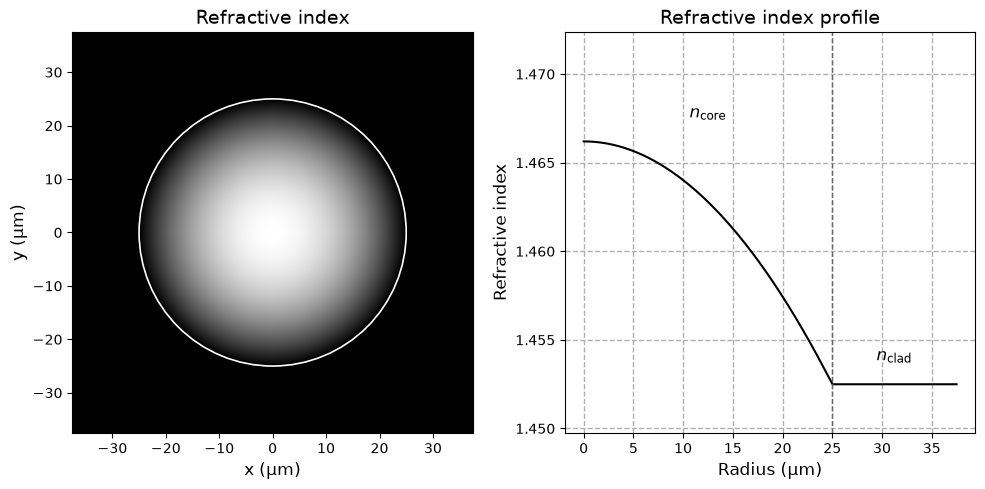

In [9]:
graded = GradedIndex(
    core_radius=r_core, r_max=r_max, n_core=n_core, na=na, alpha=2, n_samples = M//2
)
r, n_r = graded.index_1d(N=M)
graded.plot()

In [10]:
solver = RadialModeSolver(r, n_r, wavelength=wav)
modes = solver.calculate_modes()
print(f"{len(modes)} guided modes, highest |L| = {max(abs(mode.L) for mode in modes)}")

171 guided modes, highest |L| = 17


In [11]:
cartesian = solver.calculate_2d_modes(N=M)

In [12]:
modes_GI_2D = solver.modes_2D()
modes_GI_2D = modes_GI_2D / sqrt(sum(abs(modes_GI_2D)**2, axis=(1,2))[:,None,None])

In [13]:
show_modes(solver, cartesian, graded.boundary_radii())


IntSlider(value=0, description='mode', max=170)

Output()

In [14]:
modes_GI_2D.shape

(171, 512, 512)

In [15]:
sum(abs(HG[0])**2)

np.float32(1.0)

In [16]:
sum(abs(modes_GI_2D[0])**2)

np.float64(0.9999999999999999)

In [17]:
def show_pair(idx):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(complex_to_rgb(HG[idx]), origin="lower")
    ax[0].set_title(f"HG {idx}")
    ax[1].imshow(complex_to_rgb(modes_GI_2D[idx]), origin="lower")
    ax[1].set_title(f"GI {idx}")
    plt.show()

n = min(len(HG), len(modes_GI_2D)) - 1
interact(show_pair, idx=IntSlider(min=0, max=n, step=1, value=0, description="mode"))


interactive(children=(IntSlider(value=0, description='mode', max=170), Output()), _dom_classes=('widget-intera…

<function __main__.show_pair(idx)>

# Overlap ang Get MTM

In [18]:
HG.shape

(253, 512, 512)

In [19]:
HG_basis_Analytical = HG.reshape(HG.shape[0], -1)

coefs = overlaps.Modal_decomposition(HG_basis_Analytical.T, modes_GI_2D)

print(coefs.shape)


(171, 253)


(171,)


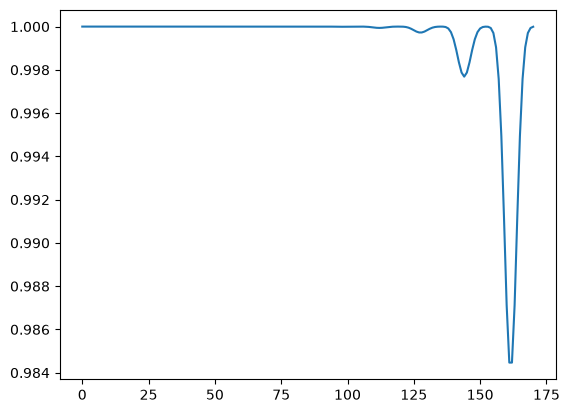

In [20]:
pow_coupled = sum(abs(coefs)**2, axis = 1)
print(pow_coupled.shape)
plot(pow_coupled)

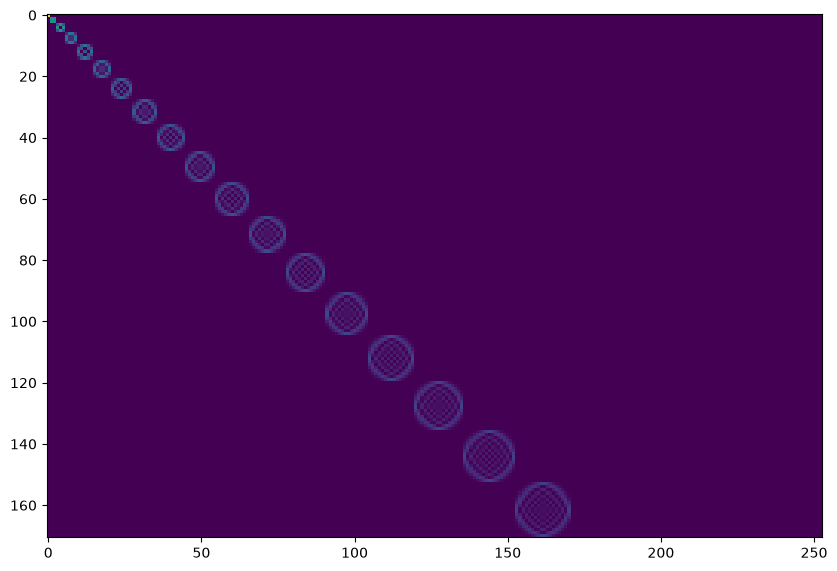

In [21]:
figsize = (10,10)
figure(figsize=figsize)
imshow(abs(coefs)**2)

# Get double Clad Modes:

In [22]:
r_clad1 = 23e-6 / 2
r_core = 4e-6 / 2
r_max = r_clad1 * 1.5
n_core = 1.45841
na_core = 0.13
na_clad1 = 0.2

N = 512

(<Figure size 1000x500 with 2 Axes>,
 array([<Axes: title={'center': 'Refractive index'}, xlabel='x (µm)', ylabel='y (µm)'>,
        <Axes: title={'center': 'Refractive index profile'}, xlabel='Radius (µm)', ylabel='Refractive index'>],
       dtype=object))

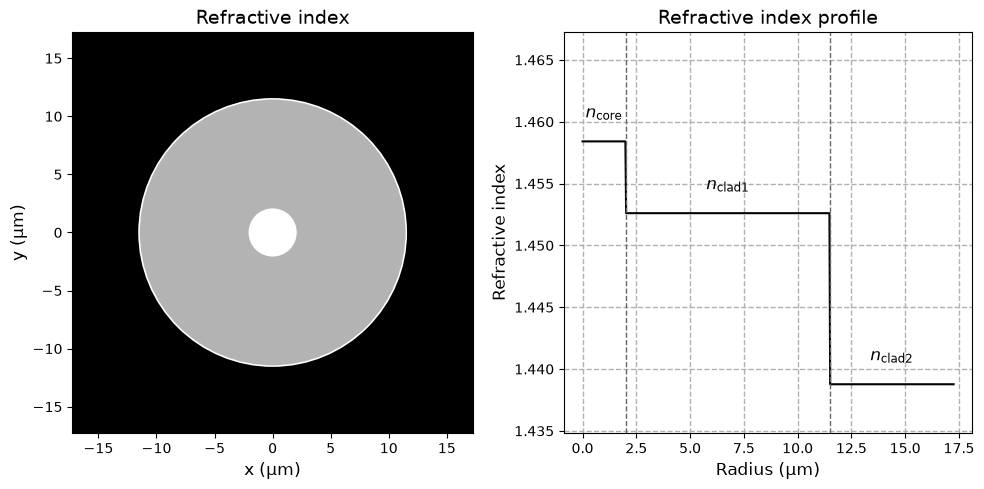

In [23]:
double_clad = DoubleClad(
    core_radius=r_core,
    clad1_radius=r_clad1,
    r_max=r_max,
    n_core=n_core,
    na_core=na_core,
    na_clad1=na_clad1,
    wavelength=wav,
)
r, n_r = double_clad.index_1d(N=N)
double_clad.plot()

In [24]:
solver = RadialModeSolver(r, n_r, wavelength=wav)
modes = solver.calculate_modes()
cartesian = solver.calculate_2d_modes(N=N)
print(f"{len(modes)} guided modes, highest |L| = {max(abs(mode.L) for mode in modes)}")
show_modes(solver, cartesian, double_clad.boundary_radii())

76 guided modes, highest |L| = 13


IntSlider(value=0, description='mode', max=75)

Output()

In [25]:
doubleClad_modes_2D = solver.modes_2D()
doubleClad_modes_2D = doubleClad_modes_2D / sqrt(sum(abs(doubleClad_modes_2D)**2, axis=(1,2))[:,None,None])

In [28]:
import numpy as np

def beam_waist(field, dx=1.0):
    """1/e² waist of a centered fundamental mode.

    field: 2D complex/real array, shape (N, N), origin at the array center.
    dx: pixel size. Leave it at 1 to get w0 in pixels (what makeHGModes wants).
    """
    intensity = np.abs(field) ** 2
    intensity /= intensity.sum()
    x = (np.arange(field.shape[-1]) - (field.shape[-1] - 1) / 2.0) * dx
    sigma_x2 = np.sum(intensity * x[None, :] ** 2)
    return 2.0 * np.sqrt(sigma_x2)

#Measure the beam waist numerically and use it as the modefield diameter for the HG, we then increase number of modes until
#all power is coupled
mode0 = solver.cartesian_modes[0].field   # L=0, M=1
Ax_solver = solver.x[1] - solver.x[0]
w0_doubleClad = beam_waist(mode0, dx=Ax_solver)  # same unit as r

w0_doubleClad_px = w0_doubleClad / Ax_solver
print(f'Double Clad Fundamental MFD {2*w0_doubleClad*1e6:0.2f} µm')

Double Clad Fundamental MFD 5.34 µm


In [28]:

from math import ceil, sqrt

def groups_for_modes(n_modes):
    G = ceil((-1 + sqrt(1 + 8 * n_modes)) / 2)
    return int(G)

def find_modeGroups(seed_guess=1, g_max=40):
    min_pow_thr = 0.98
    for G in range(seed_guess, g_max + 1):
        basis = makeHGModes(Nf=N, w0=w0_doubleClad_px, G=G)
        basis_1d = conj(basis.reshape(basis.shape[0], -1))
        coefs = overlaps.Modal_decomposition(basis_1d.T, doubleClad_modes_2D)
        min_pow = sum(abs(coefs)**2, axis=1).min()
        print(f"G = {G}, modes = {G*(G+1)//2}, min pow = {min_pow:0.3f}")
        if min_pow >= min_pow_thr:
            return G
    raise RuntimeError(f"min power stayed below {min_pow_thr} up to G = {g_max}")

In [29]:
guess_num_modes = doubleClad_modes_2D.shape[0] * 4
guess_num_groups = groups_for_modes(guess_num_modes)
print(f'Guess number of groups: {guess_num_groups}')
mg_HG_doubleClad_opt = find_modeGroups(seed_guess=guess_num_groups)
print(f'Optimal number of HG modes for double clad: {mg_HG_doubleClad_opt}')

Guess number of groups: 25
G = 25, modes = 325, min pow = 0.985
Optimal number of HG modes for double clad: 25


In [30]:
coupling_HG_basis = makeHGModes(Nf=N, w0=w0_doubleClad_px, G=mg_HG_doubleClad_opt)
coupling_HG_basis_1D = coupling_HG_basis.reshape(coupling_HG_basis.shape[0], -1)

In [31]:
ratio_modes = coupling_HG_basis.shape[0] / doubleClad_modes_2D.shape[0]
print(f'Ratio of modes: {ratio_modes}')

Ratio of modes: 4.276315789473684


In [34]:
coefs = overlaps.Modal_decomposition(coupling_HG_basis_1D.T, doubleClad_modes_2D)

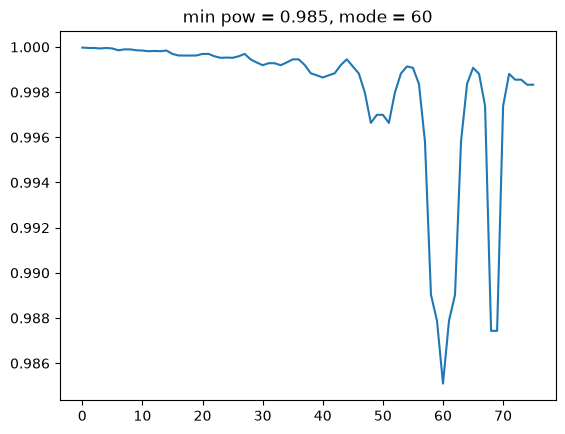

In [36]:
pow_coupled_to_HG_basis = sum(abs(coefs)**2, axis = 1)
plot(pow_coupled_to_HG_basis)
min_mode = np.argmin(pow_coupled_to_HG_basis)
min_pow = pow_coupled_to_HG_basis.min()
title(f"min pow = {min_pow:0.3f}, mode = {min_mode}")
plt.show()

(<matplotlib.image.AxesImage at 0x21c4febbb10>,
 <matplotlib.colorbar.Colorbar at 0x21c4ff1ebd0>)

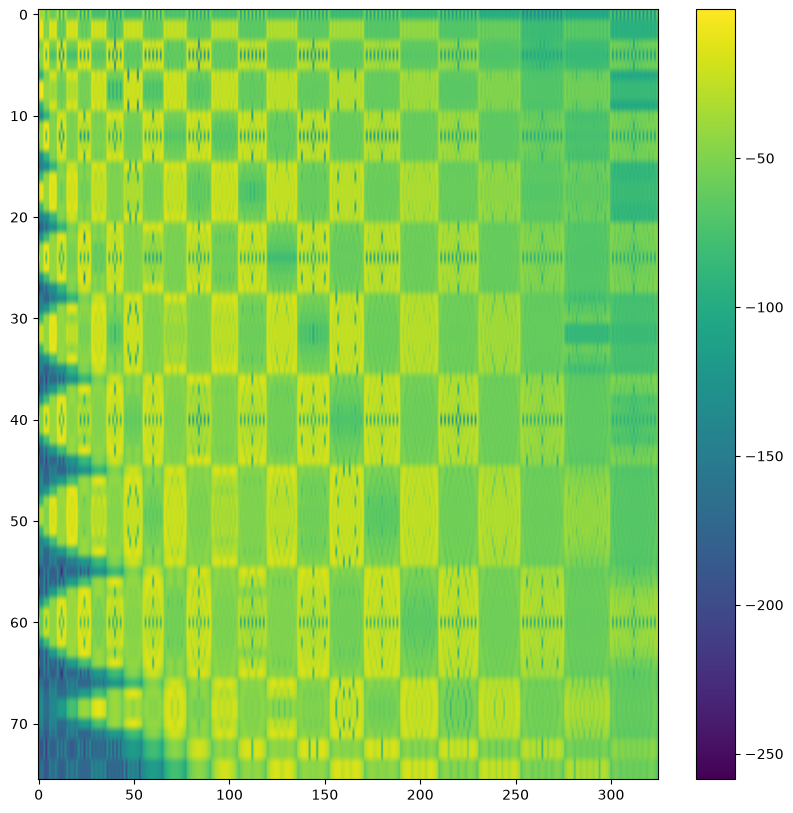

In [40]:
figsize = (10,10)
figure(figsize=figsize)
imshow(10*log10(abs(coefs)**2), aspect='auto'),colorbar()
#imshow((abs(coefs)**2)[0:20,0:20]),colorbar()

# If I would like to play with the mmf without using the solver ...

In [41]:
w0_new_px = w0_doubleClad_px * 1.2   # example: 20% larger
HG_new = makeHGModes(Nf=N, w0=w0_new_px, G=mg_HG_doubleClad_opt)
HG_new_1D = HG_new.reshape(HG_new.shape[0], -1)
rec = overlaps.Modal_reconstruction(conj(HG_new_1D.T), coefs)

In [42]:
from IPython.display import display
from ipywidgets import IntSlider, Output

window = float(solver.x[-1])
extent = [-window * 1e6, window * 1e6, -window * 1e6, window * 1e6]

with plt.ioff():
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

image_dc = axes[0].imshow(complex_to_rgb(doubleClad_modes_2D[0]), extent=extent, origin="lower")
image_rec = axes[1].imshow(complex_to_rgb(rec[0]), extent=extent, origin="lower")
for ax in axes:
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")

def update_mode(index):
    mode = solver.modes[index]
    image_dc.set_data(complex_to_rgb(doubleClad_modes_2D[index]))
    image_rec.set_data(complex_to_rgb(rec[index]))
    axes[0].set_title("double clad")
    axes[1].set_title(rf"reconstructed  $L={mode.L}$, $M={mode.M}$")
    with output:
        output.clear_output(wait=True)
        display(fig)

output = Output()
slider = IntSlider(min=0, max=len(rec) - 1, step=1, value=0, description="mode")
slider.observe(lambda change: update_mode(change["new"]), names="value")
display(slider, output)
update_mode(0)

IntSlider(value=0, description='mode', max=75)

Output()